In [52]:
!pip install pennylane

In [53]:
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# DATA

In [54]:
# Download latest version
path = kagglehub.dataset_download("hassan06/nslkdd")

print("Path to dataset files:", path)
df = pd.read_csv(path +'/KDDTrain+.txt', header=None)

print(df.shape)
df.head()

Using Colab cache for faster access to the 'nslkdd' dataset.
Path to dataset files: /kaggle/input/nslkdd
(125973, 43)


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [55]:
#
X_brut=df.iloc[:,0:41]
y_brut=df.iloc[:,41]
# Binary Encoding of Labels
y_binaire=pnp.where(y_brut=='normal',-1.0, 1.0)
# pretraitment
X_encode= pd.get_dummies(X_brut, columns=[1,2,3], drop_first=True)
indices=pnp.random.choice(X_encode.shape[0],200, replace=False)
X_sub=X_encode.iloc[indices].values
y_sub=y_binaire[indices]
# PCA & Scaling [0 , pi]
pca= PCA(n_components=4)
X_pca=pca.fit_transform(X_sub)
scaler=MinMaxScaler(feature_range=(0,pnp.pi))
X_scaled =scaler.fit_transform(X_pca)
# Splitting

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_sub, test_size=0.2, random_state=42)

# Quantum circuit

In [56]:
N_QUBITS=4
N_LAYERS= 2 # ansatz layers
dev = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(dev)
def vqc_circuit(weights,x):
  # A. Feature Map
  qml.AngleEmbedding(x, wires=range(N_QUBITS))
  # B. Ansatz Variational
  qml.StronglyEntanglingLayers(weights, wires= range(N_QUBITS))

  # C. Measurement
  return qml.expval(qml.PauliZ(0))

 # COST FUNCTION AND OPTIMIZATION

In [57]:
def cost_function(weights, X_batch, y_batch):
  predictions=[vqc_circuit(weights,x) for x in X_batch]
  # Mean Squared Error (MSE)
  return pnp.mean((pnp.array(predictions)-y_batch)**2)

def accuracy(weights, X_batch, y_batch):
  preds=[pnp.sign(vqc_circuit(weights, x)) for x in X_batch]
  return pnp.mean(pnp.array(preds)==y_batch)

# Random initialization of the circuit's weights
pnp.random.seed(42)
weights=pnp.random.random(size=qml.StronglyEntanglingLayers.shape(n_layers=N_LAYERS,n_wires=N_QUBITS))

# Quantum optimizer (Adam or GradientDescent)
opt= qml.AdamOptimizer(stepsize=0.1)


# Training

In [58]:
epochs=25
batch_size=32

loss_history = []
acc_history = []

print("Start of VQC practice...\n")

for epoch in range(epochs):
  batch_index=pnp.random.choice(len(X_train),batch_size,replace=False)
  X_b=X_train[batch_index]
  y_b=y_train[batch_index]

  weights, cost = opt.step_and_cost(lambda w: cost_function(w, X_b, y_b), weights)
  loss_history.append(cost)

  acc_current = accuracy(weights, X_train, y_train)
  acc_history.append(acc_current)

  if (epoch+1)%5==0 or epoch==0:
    print(f"Epoch {epoch+1:2d}/{epochs} | Loss: {cost:.4f} | Training Accuracy: {acc_current*100:.1f}%")

Start of VQC practice...

Epoch  1/25 | Loss: 1.1119 | Training Accuracy: 50.6%
Epoch  5/25 | Loss: 0.8957 | Training Accuracy: 59.4%
Epoch 10/25 | Loss: 0.7596 | Training Accuracy: 83.8%
Epoch 15/25 | Loss: 0.7734 | Training Accuracy: 84.4%
Epoch 20/25 | Loss: 0.4641 | Training Accuracy: 85.0%
Epoch 25/25 | Loss: 0.7383 | Training Accuracy: 84.4%


# EVALUATION ON THE TEST SET

In [59]:
acc_test=accuracy(weights, X_test,y_test)
print(f"Test Accuracy: {acc_test*100:.1f}%")

Test Accuracy: 85.0%


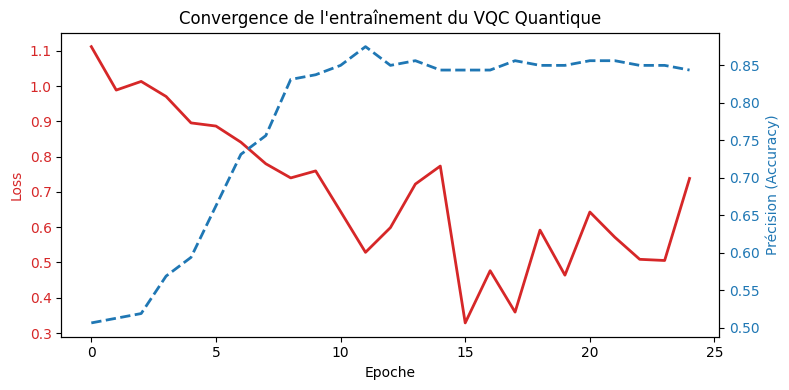

In [60]:
fig, ax1=plt.subplots(figsize=(8,4))
color='tab:red'
ax1.set_xlabel("Epoche")
ax1.set_ylabel("Loss", color=color)
ax1.plot(loss_history, color=color, linewidth=2,label='Loss')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Précision (Accuracy)', color=color)
ax2.plot(acc_history, color=color, linewidth=2, linestyle='--', label='Accuracy')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Convergence de l'entraînement du VQC Quantique")
fig.tight_layout()
plt.show()


# CONFUSION MATRIX ON THE TEST SET

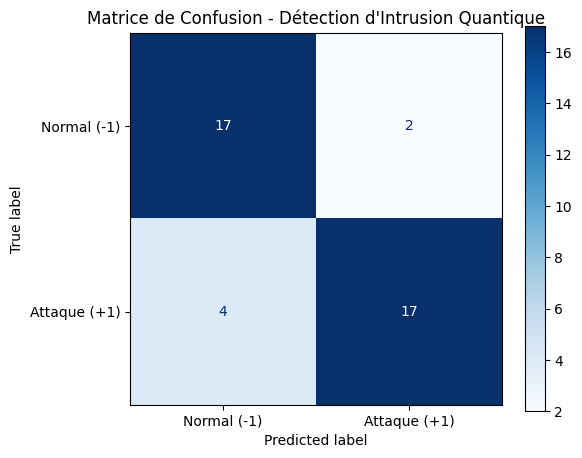

In [61]:
y_pred = [pnp.sign(vqc_circuit(weights, x)) for x in X_test]

cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal (-1)', 'Attaque (+1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax)
plt.title("Matrice de Confusion - Détection d'Intrusion Quantique")
plt.show()

#